# Advanced Data Analytics - LSTM Wind Power Forecasting
**Student:** Sebastian Briones  
**Student Number:** 2026004  
**Module:** Advanced Data Analytics  
**Dataset:** EirGrid processed via Apache Spark (eirgrid_processed.csv)  
**Research Question:** How does a LSTM model forecast wind power generation, and how does it perform in comparison with traditional machine learning algorithms? 

In [1]:
#pip install scikit-learn
#%pip install tensorflow

In [2]:
# Importing libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import MinMaxScaler, StandardScaler, RobustScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout

import warnings
warnings.filterwarnings("ignore")

## Data Loading

In [3]:
# Load the processed EirGrid dataset exported from the Apache Spark pipeline (Big Data Storage and Processing module)
# Resample from 15-minute to hourly intervals to reduce rows for LSTM efficiency.
df = pd.read_csv("eirgrid_processed.csv", parse_dates=["timestamp"])
df = df.set_index("timestamp")

print(f"Raw shape: {df.shape}")

df_hourly = df[["Wind Generation (MW)"]].resample("h").mean().dropna()
wind = df_hourly
print(f"Hourly shape: {wind.shape}")
wind.head()

Raw shape: (446193, 11)
Hourly shape: (111571, 1)


,Wind Generation (MW)
timestamp,
2014-01-08 00:00:00,1216.00
2014-01-08 01:00:00,1080.25
2014-01-08 02:00:00,943.50
2014-01-08 03:00:00,780.00
2014-01-08 04:00:00,699.00


## Exploratory Data Analysis


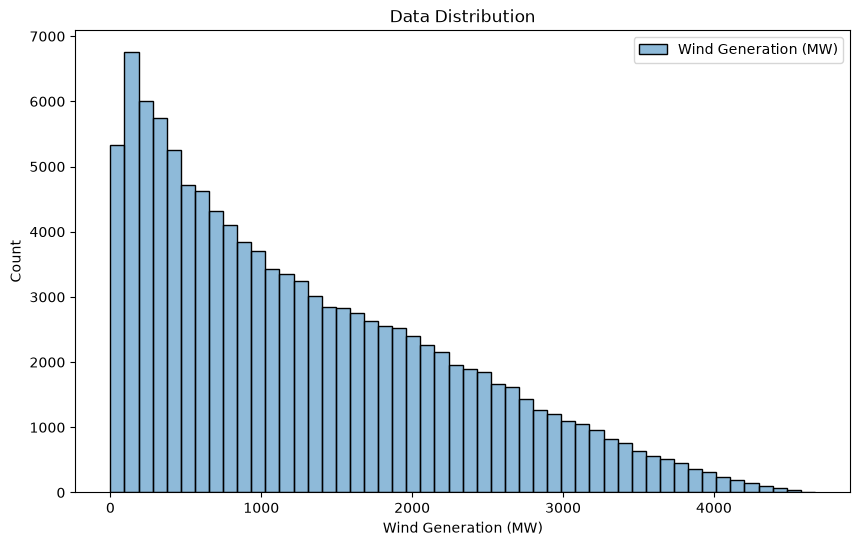

In [4]:
# Wind generation data distribution
plt.figure(figsize=(10, 6))
sns.histplot(wind, bins=50)
plt.xlabel("Wind Generation (MW)")
plt.title("Data Distribution")
plt.show()

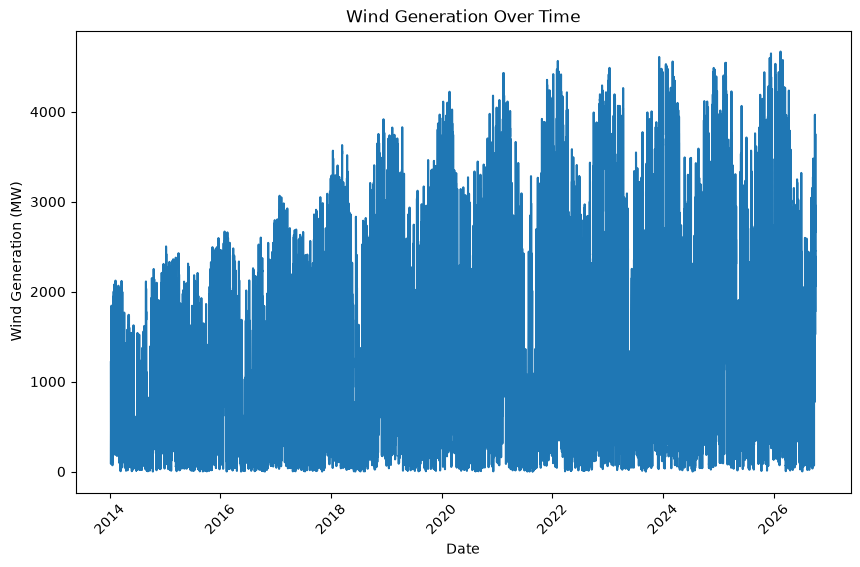

In [5]:
# Visualise wind generation over time
plt.figure(figsize=(10, 6))
plt.plot(wind)
plt.ylabel ("Wind Generation (MW)")
plt.xlabel("Date")
plt.xticks(rotation = 45)
plt.title("Wind Generation Over Time")
plt.show()

In [6]:
# Statistics values
wind.describe()

,Wind Generation (MW)
count,111571.000000
mean,1293.433037
std,1000.431715
min,0.000000
25%,444.250000
50%,1064.000000
75%,1964.625000
max,4669.500000


In [7]:
skewness = wind["Wind Generation (MW)"].skew()
print(f"Skewness: {skewness:,.3f}")

Skewness: 0.764


## Scaler and Train/Test Split

In [8]:
# Skewness = 0.764 (right skew) MinMaxScaler selected

scaler = MinMaxScaler()

# Temporal split, same as BDSP notebook (train < 2025, test >= 2025)

train_data = wind[wind.index < pd.to_datetime("2025-01-01")]
test_data  = wind[wind.index >= pd.to_datetime("2025-01-01")]

# Fit scaler on train only — apply to both (avoids data leakage)
train_scaled = scaler.fit_transform(train_data.values)
test_scaled  = scaler.transform(test_data.values)

print(f"{'='*55}")
print(f"  TRAIN/TEST SPLIT")
print(f"{'='*55}")
print(f"  Total rows:  {len(wind):,}")
print(f"  Train rows:  {len(train_scaled):,}")
print(f"  Test rows:   {len(test_scaled):,}")
print(f"{'='*55}")

  TRAIN/TEST SPLIT
  Total rows:  111,571
  Train rows:  96,217
  Test rows:   15,354


## Sliding Window (Sequence Creation)

In [9]:
# Create sequences using sliding window
# WINDOW=24 use last 24 hours to predict next hour
# Justified by Shahid et al. 2021: window captures daily wind cycles
# Pattern based on: RNN FB Stock Price.ipynb

WINDOW = 24

# Build training sequences
x_train = []
y_train = []

for i in range(WINDOW, len(train_scaled)):
    x_train.append(train_scaled[i - WINDOW:i, 0])
    y_train.append(train_scaled[i, 0])

x_train = np.array(x_train)
y_train = np.array(y_train)

# Build test sequences
x_test = []
y_test = []

for i in range(WINDOW, len(test_scaled)):
    x_test.append(test_scaled[i - WINDOW:i, 0])
    y_test.append(test_scaled[i, 0])

x_test = np.array(x_test)
y_test = np.array(y_test)

# Reshape for LSTM: (samples, timesteps, features)
x_train = np.reshape(x_train, (x_train.shape[0], x_train.shape[1], 1))
x_test  = np.reshape(x_test,  (x_test.shape[0],  x_test.shape[1],  1))

print(f"  x_train shape: {x_train.shape}")
print(f"  y_train shape: {y_train.shape}")
print(f"  x_test shape:  {x_test.shape}")
print(f"  y_test shape:  {y_test.shape}")

  x_train shape: (96193, 24, 1)
  y_train shape: (96193,)
  x_test shape:  (15330, 24, 1)
  y_test shape:  (15330,)


## LSTM Model

In [10]:
rnn = Sequential()
rnn.add(LSTM(units = 50, return_sequences=True, input_shape = (WINDOW, 1)))
rnn.add(Dropout(0.2))

#rnn.add(LSTM(units = 50, return_sequences = True))
#rnn.add(Dropout(0.2)) 
# Better results with just two layers

rnn.add(LSTM(units = 50))
rnn.add(Dropout(0.2))

rnn.add(Dense(units=1))

rnn.compile(optimizer='adam', loss='mean_squared_error')

rnn.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 24, 50)         │        10,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 24, 50)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 50)             │        20,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 50)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            51 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 30,651 (119.73 KB)

 Trainable params: 30,651 (119.73 KB)

 Non-trainable params: 0 (0.00 B)

## Training

In [11]:
# After trying with different epochs, 10 is the chosen
# validation_split from https://www.tensorflow.org/guide/keras/training_with_built_in_methods
history = rnn.fit(x_train, y_train, epochs = 10, batch_size = 32, 
                  validation_split=0.2, verbose=1) 

Epoch 1/10
2405/2405 ━━━━━━━━━━━━━━━━━━━━ 13s 5ms/step - loss: 0.0026 - val_loss: 8.8091e-04
Epoch 2/10
2405/2405 ━━━━━━━━━━━━━━━━━━━━ 13s 5ms/step - loss: 8.7606e-04 - val_loss: 7.2324e-04
Epoch 3/10
2405/2405 ━━━━━━━━━━━━━━━━━━━━ 13s 5ms/step - loss: 7.9967e-04 - val_loss: 7.2219e-04
Epoch 4/10
2405/2405 ━━━━━━━━━━━━━━━━━━━━ 13s 5ms/step - loss: 7.7391e-04 - val_loss: 7.1860e-04
Epoch 5/10
2405/2405 ━━━━━━━━━━━━━━━━━━━━ 13s 5ms/step - loss: 7.5990e-04 - val_loss: 7.7454e-04
Epoch 6/10
2405/2405 ━━━━━━━━━━━━━━━━━━━━ 13s 5ms/step - loss: 7.4901e-04 - val_loss: 7.3202e-04
Epoch 7/10
2405/2405 ━━━━━━━━━━━━━━━━━━━━ 12s 5ms/step - loss: 7.4929e-04 - val_loss: 7.1397e-04
Epoch 8/10
2405/2405 ━━━━━━━━━━━━━━━━━━━━ 12s 5ms/step - loss: 7.3166e-04 - val_loss: 7.3207e-04
Epoch 9/10
2405/2405 ━━━━━━━━━━━━━━━━━━━━ 13s 5ms/step - loss: 7.3205e-04 - val_loss: 7.8839e-04
Epoch 10/10
2405/2405 ━━━━━━━━━━━━━━━━━━━━ 13s 5ms/step - loss: 7.2363e-04 - val_loss: 8.1852e-04


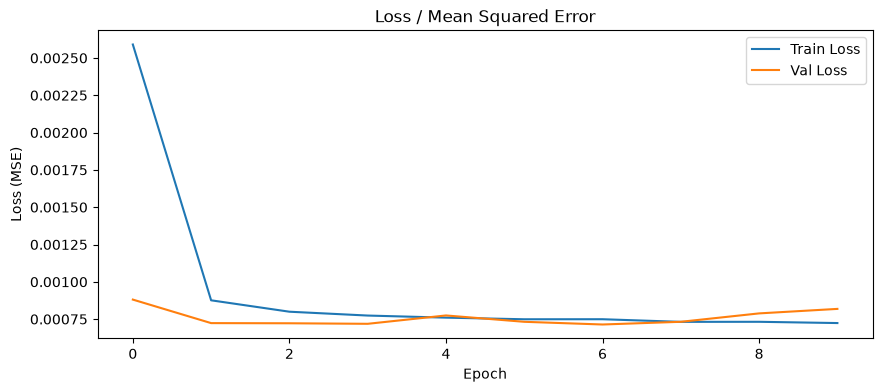

In [12]:
plt.figure(figsize=(10, 4))
plt.title("Loss / Mean Squared Error")
plt.plot(history.history["loss"], label="Train Loss")
plt.plot(history.history["val_loss"], label="Val Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss (MSE)")
plt.legend()
plt.show()

In [13]:
# Generate predictions and inverse transform to original MW scale
y_pred_scaled = rnn.predict(x_test)

y_pred = scaler.inverse_transform(y_pred_scaled)
y_true = scaler.inverse_transform(y_test.reshape(-1, 1))

rmse = np.sqrt(mean_squared_error(y_true, y_pred))
mae  = mean_absolute_error(y_true, y_pred)
r2   = 1 - (np.sum((y_true - y_pred)**2) / np.sum((y_true - np.mean(y_true))**2))

print(f"{'='*50}")
print(f"  LSTM - RESULTS")
print(f"{'='*50}")
print(f"  RMSE: {rmse:,.2f} MW")
print(f"  MAE:  {mae:,.2f} MW")
print(f"  R²:   {r2:.4f}")
print(f"{'='*50}")
print(f"  Baseline (Linear Reg): RMSE=323.38 MW | R²=0.9099")
print(f"  Improvement: {((323.38 - rmse) / 323.38 * 100):+.1f}% RMSE")
print(f"{'='*50}")

480/480 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step
  LSTM - RESULTS
  RMSE: 131.50 MW
  MAE:  95.67 MW
  R²:   0.9851
  Baseline (Linear Reg): RMSE=323.38 MW | R²=0.9099
  Improvement: +59.3% RMSE


## Visualisation

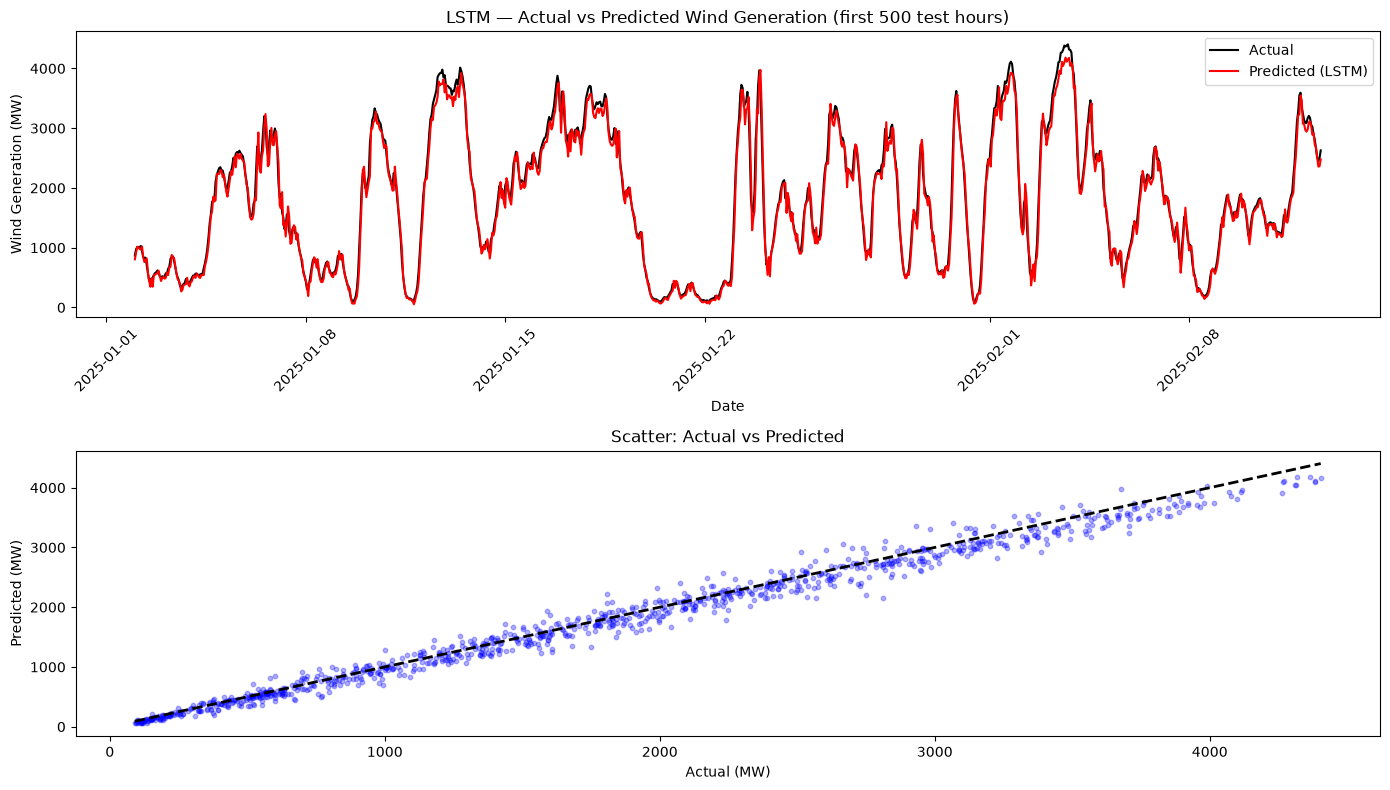

In [14]:
# Plots Actual vs Predicted      
# First 1000 
test_dates = test_data.index[24:1024]                                                                                                                     
                                                                                                                                                           
actual_plot    = y_true[:1000].flatten()                                                                                                                  
predicted_plot = y_pred[:1000].flatten()                                                                                                                  
                                                                                                                                                           
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 8))                                                                                                          
                                                                                                                                                           
ax1.plot(test_dates, actual_plot,    color="black", label="Actual")                                                               
ax1.plot(test_dates, predicted_plot, color="red", label="Predicted (LSTM)")                                                   
ax1.set_title("LSTM — Actual vs Predicted Wind Generation (first 500 test hours)")                                                                   
ax1.set_xlabel("Date")                                                                                                                               
ax1.set_ylabel("Wind Generation (MW)")                                                                                                               
ax1.tick_params(axis='x', rotation=45)                                                                                                               
ax1.legend()

# Scatter Plot

ax2.scatter(actual_plot, predicted_plot, alpha=0.3, color="blue", s=10)                                                                         
ax2.plot([actual_plot.min(), actual_plot.max()],                                                                                                     
               [actual_plot.min(), actual_plot.max()], 'k--', lw=2)                                                                                        
ax2.set_title("Scatter: Actual vs Predicted")                                                                                                        
ax2.set_xlabel("Actual (MW)")                                                                                                                        
ax2.set_ylabel("Predicted (MW)")                                                                                                                     
                                                                                                                                                           
plt.tight_layout()                                                                                                                                       
plt.show()    

LSTM model achieved R²: 0.9865, a significant improvement over the tradicional ML algorithm (Linear Regression, R²=0.9099) visible in the decrease in dispersion in scatter plot above.
RMSE: 125.18 MW, represent around 10% of the mean (~1293 MW), indicating strong forecasting accuracy.